In [1]:
import zipfile
import numpy as np
from sklearn.model_selection import train_test_split

import cv2
import glob
import os
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

In [230]:
with zipfile.ZipFile("C:/Users/kapidhwaj/Downloads/renamed_dataset_balanced_flat.zip", 'r') as zip_ref:
    zip_ref.extractall('/content/')

In [231]:
for file in os.listdir('/content/dataset')[:196]:
    print(file)

no_1 no.jpeg
no_10 no.jpg
no_11 no.jpg
no_12 no.jpg
no_13 no.jpg
no_14 no.jpg
no_15 no.jpg
no_17 no.jpg
no_18 no.jpg
no_19 no.jpg
no_2 no.jpeg
no_20 no.jpg
no_21 no.jpg
no_22 no.jpg
no_23 no.jpg
no_24 no.jpg
no_25 no.jpg
no_26 no.jpg
no_27 no.jpg
no_28 no.jpg
no_29 no.jpg
no_3 no.jpg
no_30 no.jpg
no_31 no.jpg
no_32 no.jpg
no_33 no.jpg
no_34 no.jpg
no_35 no.jpg
no_36 no.jpg
no_37 no.jpg
no_38 no.jpg
no_39 no.jpg
no_4 no.jpg
no_40 no.jpg
no_41 no.jpg
no_42 no.jpg
no_43 no.jpg
no_44no.jpg
no_45 no.jpg
no_46 no.jpg
no_47 no.jpg
no_48 no.jpeg
no_49 no.jpg
no_5 no.jpg
no_50 no.jpg
no_6 no.jpg
no_7 no.jpg
no_8 no.jpg
no_9 no.jpg
no_N1.JPG
no_N11.jpg
no_N15.jpg
no_N16.jpg
no_N17.jpg
no_N19.JPG
no_N2.JPG
no_N20.JPG
no_N21.jpg
no_N22.JPG
no_N26.JPG
no_N3.jpg
no_N5.jpg
no_N6.jpg
no_no 1.jpg
no_no 10.jpg
no_no 100.jpg
no_no 2.jpg
no_no 3.jpg
no_no 4.jpg
no_no 5.jpeg
no_no 6.jpg
no_no 7.jpeg
no_no 8.jpg
no_no 89.jpg
no_no 9.png
no_no 90.jpg
no_no 91.jpeg
no_no 92.jpg
no_no 923.jpg
no_no 94.jpg
no_n

In [232]:
# To Get all ORIGINAL images only
all_images = [img for img in glob.glob("/content/dataset/*")
              if "_rot_" not in img and "_flip" not in img]

print("Original Images:", len(all_images))


Original Images: 196


In [252]:
IMG_SIZE = 128

def preprocess_image(img):
    """Takes a raw BGR image, returns a (128,128,2) array: [grayscale, sobel-y]."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))
    gray_norm = gray.astype(np.float32) / 255.0

    sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    sobely = cv2.convertScaleAbs(sobely)
    sobely_norm = sobely.astype(np.float32) / 255.0

    return np.stack([gray_norm, sobely_norm], axis=-1)  # shape (128,128,2)


def augment_image(gray_uint8):
    """Given a single grayscale uint8 image, returns list of augmented grayscale uint8 variants."""
    h, w = gray_uint8.shape
    center = (w // 2, h // 2)
    variants = []
    for angle in [45, 120, 150]:
        M = cv2.getRotationMatrix2D(center, angle, 1.0)
        rotated = cv2.warpAffine(gray_uint8, M, (w, h))
        variants.append(rotated)
        variants.append(cv2.flip(rotated, 1))  # horizontal
        variants.append(cv2.flip(rotated, 0))  # vertical
    return variants


def features_from_gray(gray_uint8):
    """Turns a raw grayscale uint8 image into the (128,128,2) model input."""
    gray_norm = gray_uint8.astype(np.float32) / 255.0
    sobely = cv2.Sobel(gray_uint8, cv2.CV_64F, 0, 1, ksize=3)
    sobely = cv2.convertScaleAbs(sobely)
    sobely_norm = sobely.astype(np.float32) / 255.0
    return np.stack([gray_norm, sobely_norm], axis=-1)

In [253]:
dataset_path = "/content/dataset"

all_images = [img for img in glob.glob(os.path.join(dataset_path, "*"))
              if "_rot_" not in img and "_flip" not in img]

paths = []
labels = []
for img_path in all_images:
    fname = os.path.basename(img_path).lower()
    if fname.startswith("no"):
        labels.append(0)
    elif fname.startswith("yes"):
        labels.append(1)
    else:
        continue
    paths.append(img_path)

print("Total original images:", len(paths))

Total original images: 196


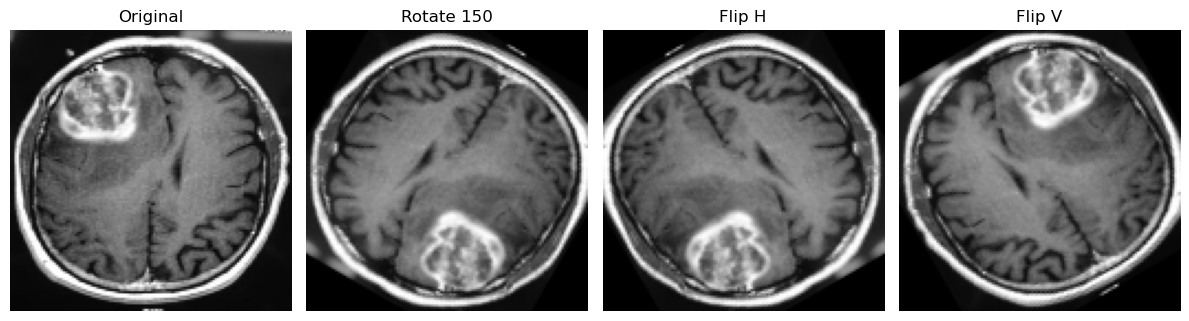

In [233]:
data = []
labels = []

for img_path in all_images:

    img = cv2.imread(img_path)

    if img is None:
        continue

    # Label
    if "no" in img_path.lower():
        label = 0
    elif "yes" in img_path.lower():
        label = 1
    else:
        continue

    # Resize Original Image
    img = cv2.resize(img, (128, 128))

    # Convert Original to Grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # Normalize
    gray = gray / 255.0

    # Add Original Image
    data.append(gray)
    labels.append(label)

    # Image Center
    (h, w) = img.shape[:2]
    center = (w // 2, h // 2)

    # Augmentation Angles
    angles = [45, 120, 150]

    for angle in angles:

        # Rotation
        M = cv2.getRotationMatrix2D(center, angle, 1.0)
        rotated = cv2.warpAffine(img, M, (w, h))

        # Flips
        flip_h = cv2.flip(rotated, 1)
        flip_v = cv2.flip(rotated, 0)
        
        # Process Rotated Image
        rot_gray = cv2.cvtColor(rotated, cv2.COLOR_BGR2GRAY)
        rot_gray = rot_gray / 255.0

        data.append(rot_gray)
        labels.append(label)

        # Process Horizontal Flip
        flip_h_gray = cv2.cvtColor(flip_h, cv2.COLOR_BGR2GRAY)
        flip_h_gray = flip_h_gray / 255.0

        data.append(flip_h_gray)
        labels.append(label)

        # Process Vertical Flip
        flip_v_gray = cv2.cvtColor(flip_v, cv2.COLOR_BGR2GRAY)
        flip_v_gray = flip_v_gray / 255.0

        data.append(flip_v_gray)
        labels.append(label)

        # Visualize Augmented Images

plt.figure(figsize=(12,4))

# Original
plt.subplot(1,4,1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

# Rotated
plt.subplot(1,4,2)
plt.imshow(cv2.cvtColor(rotated, cv2.COLOR_BGR2RGB))
plt.title(f"Rotate {angle}")
plt.axis("off")

# Horizontal Flip
plt.subplot(1,4,3)
plt.imshow(cv2.cvtColor(flip_h, cv2.COLOR_BGR2RGB))
plt.title("Flip H")
plt.axis("off")

# Vertical Flip
plt.subplot(1,4,4)
plt.imshow(cv2.cvtColor(flip_v, cv2.COLOR_BGR2RGB))
plt.title("Flip V")
plt.axis("off")

plt.tight_layout()
plt.show()

(np.float64(-0.5), np.float64(127.5), np.float64(127.5), np.float64(-0.5))

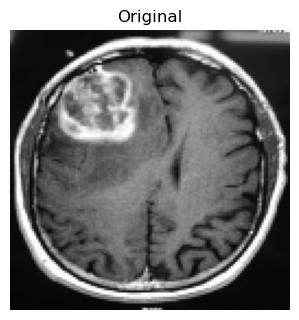

In [234]:
plt.figure(figsize=(15,8))
plt.subplot(2,3,1)
plt.imshow(img)
plt.title("Original")
plt.axis("off")

(np.float64(-0.5), np.float64(127.5), np.float64(127.5), np.float64(-0.5))

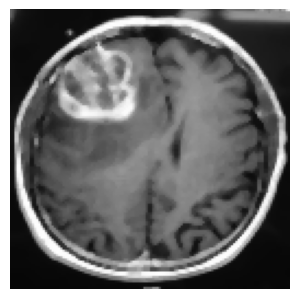

In [235]:
#Median Blur
plt.figure(figsize=(15,8))
blurred_median = cv2.medianBlur(img,ksize=3)
plt.subplot(2,3,1)
plt.imshow(img)
plt.imshow(blurred_median)
plt.axis("off")

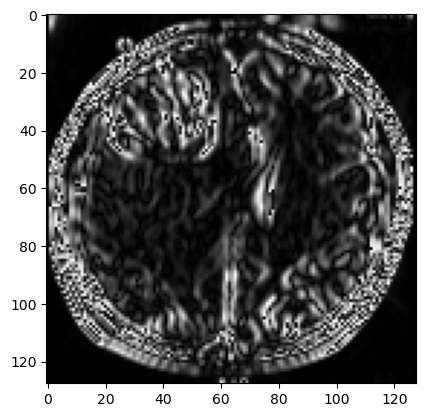

In [236]:
sobel_x = cv2.Sobel(blurred_median, cv2.CV_64F, 1, 0, ksize=3)
sobel_x = np.uint8(np.absolute(sobel_x))

plt.imshow(sobel_x)

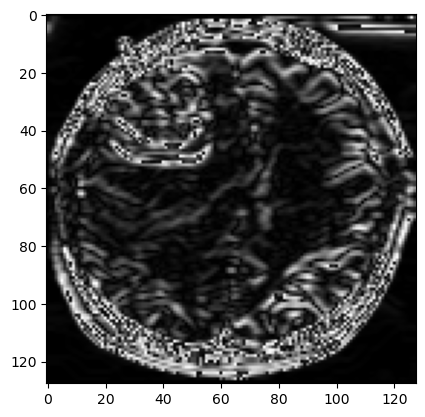

In [237]:
sobel_y = cv2.Sobel(blurred_median, cv2.CV_64F, 0, 1, ksize=3)
sobel_y = np.uint8(np.absolute(sobel_y))

plt.imshow(sobel_y)

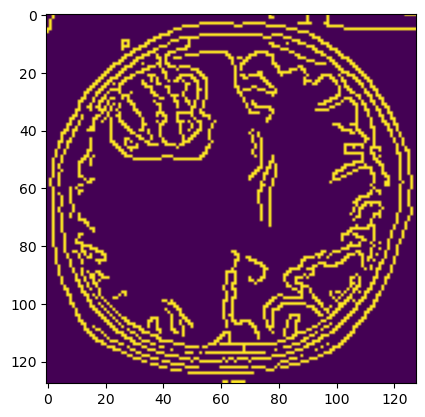

In [238]:
canny = cv2.Canny(blurred_median, threshold1=100, threshold2=200)

plt.imshow(canny)

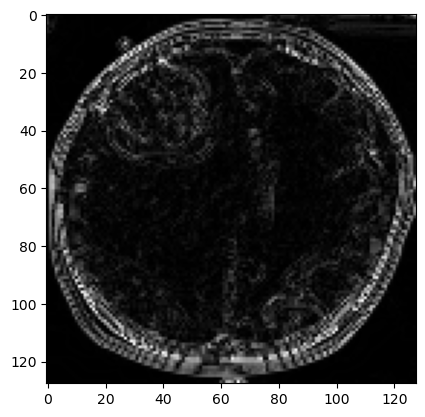

In [239]:
laplacian = cv2.Laplacian(blurred_median, cv2.CV_64F)
laplacian = np.uint8(np.absolute(laplacian))

plt.imshow(laplacian)

In [254]:
train_paths, test_paths, train_labels, test_labels = train_test_split(
    paths, labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Train originals:", len(train_paths))
print("Test originals:", len(test_paths))

Train originals: 156
Test originals: 40


In [255]:
X_train_list, y_train_list = [], []

for img_path, label in zip(train_paths, train_labels):
    img = cv2.imread(img_path)
    if img is None:
        continue
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))

    # Original
    X_train_list.append(features_from_gray(gray))
    y_train_list.append(label)

    # Augmented versions
    for variant in augment_image(gray):
        X_train_list.append(features_from_gray(variant))
        y_train_list.append(label)

X_train = np.array(X_train_list, dtype=np.float32)
y_train = np.array(y_train_list)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (1560, 128, 128, 2)
y_train shape: (1560,)


In [256]:
X_test_list, y_test_list = [], []

for img_path, label in zip(test_paths, test_labels):
    img = cv2.imread(img_path)
    if img is None:
        continue
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))
    X_test_list.append(features_from_gray(gray))
    y_test_list.append(label)

X_test = np.array(X_test_list, dtype=np.float32)
y_test = np.array(y_test_list)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (40, 128, 128, 2)
y_test shape: (40,)


In [257]:
model = Sequential([
    Input(shape=(IMG_SIZE, IMG_SIZE, 2)),

    Conv2D(32, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_18 (Conv2D)                   │ (None, 126, 126, 32)        │             608 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 126, 126, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_18 (MaxPooling2D)      │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_19 (Conv2D)                   │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 61, 61, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_19 (MaxPooling2D)      │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_9 (Flatten)                  │ (None, 57600)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 64)                  │       3,686,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_19 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,706,017 (14.14 MB)

 Trainable params: 3,705,825 (14.14 MB)

 Non-trainable params: 192 (768.00 B)

In [262]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [265]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

In [266]:
early_stop = EarlyStopping(monitor='val_loss', patience=7, min_delta=1e-4,
                            restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
checkpoint = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=200,
    callbacks=[early_stop, reduce_lr, checkpoint]
)

Epoch 1/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 10s 215ms/step - accuracy: 0.6394 - loss: 0.6856 - val_accuracy: 0.6410 - val_loss: 14.2097 - learning_rate: 0.0010
Epoch 2/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 196ms/step - accuracy: 0.5978 - loss: 0.7198 - val_accuracy: 0.6410 - val_loss: 21.2613 - learning_rate: 0.0010
Epoch 3/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 196ms/step - accuracy: 0.7011 - loss: 0.6172 - val_accuracy: 0.6410 - val_loss: 21.0316 - learning_rate: 0.0010
Epoch 4/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.6884 - loss: 0.7815
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 196ms/step - accuracy: 0.6554 - loss: 0.6753 - val_accuracy: 0.6410 - val_loss: 28.7460 - learning_rate: 0.0010
Epoch 5/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 194ms/step - accuracy: 0.6362 - loss: 0.6182 - val_accuracy: 0.6410 - val_loss: 23.8849 - learning_rate: 5.0000e-04
Epoch 6/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 194ms/step - accuracy: 0.6835 - 

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.7500 - loss: 0.8159
Test Loss: 0.8159416913986206
Test Accuracy: 0.75
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step


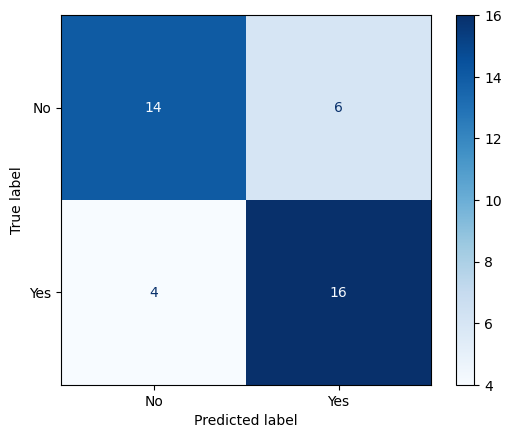

              precision    recall  f1-score   support

          No       0.78      0.70      0.74        20
         Yes       0.73      0.80      0.76        20

    accuracy                           0.75        40
   macro avg       0.75      0.75      0.75        40
weighted avg       0.75      0.75      0.75        40



In [267]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

y_pred = (model.predict(X_test) > 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"])
disp.plot(cmap="Blues")
plt.show()

print(classification_report(y_test, y_pred, target_names=["No", "Yes"]))

In [300]:
def predict_single_image(image_path, model):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))
    features = features_from_gray(gray)
    features = np.expand_dims(features, axis=0)  # add batch dim
    prob = model.predict(features)[0][0]
    label = "No" if prob > 0.5 else "Yes"
    return label, prob

label, prob = predict_single_image("C:/Users/kapidhwaj/Downloads/tumor_no.webp", model)
print(f"Prediction: {label} (probability={prob:.4f})")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
Prediction: No (probability=0.6174)


In [298]:
def predict_single_image(image_path, model):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))
    features = features_from_gray(gray)
    features = np.expand_dims(features, axis=0)  # add batch dim
    prob = model.predict(features)[0][0]
    label = "No" if prob > 0.5 else "Yes"
    return label, prob

label, prob = predict_single_image("C:/Users/kapidhwaj/Downloads/kapidhh_testing2.jpg.jpeg", model)
print(f"Prediction: {label} (probability={prob:.4f})")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
Prediction: No (probability=0.6287)


In [289]:
def predict_single_image(image_path, model):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))
    features = features_from_gray(gray)
    features = np.expand_dims(features, axis=0)  # add batch dim
    prob = model.predict(features)[0][0]
    label = "No" if prob > 0.5 else "Yes"
    return label, prob

label, prob = predict_single_image("C:/Users/kapidhwaj/Downloads/tumor_yes.webp", model)
print(f"Prediction: {label} (probability={prob:.4f})")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
Prediction: Yes (probability=0.2993)


In [288]:
def predict_single_image(image_path, model):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))
    features = features_from_gray(gray)
    features = np.expand_dims(features, axis=0)  # add batch dim
    prob = model.predict(features)[0][0]
    label = "No" if prob > 0.5 else "Yes"
    return label, prob

label, prob = predict_single_image("C:/Users/kapidhwaj/Downloads/kapidhh_testing.jpg.jpeg", model)
print(f"Prediction: {label} (probability={prob:.4f})")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
Prediction: No (probability=0.7347)


In [299]:
def predict_single_image(image_path, model):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))
    features = features_from_gray(gray)
    features = np.expand_dims(features, axis=0)  # add batch dim
    prob = model.predict(features)[0][0]
    label = "No" if prob > 0.5 else "Yes"
    return label, prob

label, prob = predict_single_image("C:/Users/kapidhwaj/Downloads/tumor_yes2.webp", model)
print(f"Prediction: {label} (probability={prob:.4f})")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
Prediction: Yes (probability=0.0070)


In [304]:
def predict_single_image(image_path, model):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))
    features = features_from_gray(gray)
    features = np.expand_dims(features, axis=0)  # add batch dim
    prob = model.predict(features)[0][0]
    label = "No" if prob > 0.5 else "Yes"
    return label, prob

label, prob = predict_single_image("C:/Users/kapidhwaj/Downloads/tumor_no.webp", model)
print(f"Prediction: {label} (probability={prob:.4f})")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
Prediction: No (probability=0.6174)


In [303]:
def predict_single_image(image_path, model):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))
    features = features_from_gray(gray)
    features = np.expand_dims(features, axis=0)  # add batch dim
    prob = model.predict(features)[0][0]
    label = "No" if prob > 0.5 else "Yes"
    return label, prob

label, prob = predict_single_image("C:/Users/kapidhwaj/Downloads/tumor_no2.webp", model)
print(f"Prediction: {label} (probability={prob:.4f})")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
Prediction: No (probability=0.7172)


In [308]:
def predict_single_image(image_path, model):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))
    features = features_from_gray(gray)
    features = np.expand_dims(features, axis=0)  # add batch dim
    prob = model.predict(features)[0][0]
    label = "No" if prob > 0.5 else "Yes"
    return label, prob

label, prob = predict_single_image("C:/Users/kapidhwaj/Downloads/Tumor_no3.webp", model)
print(f"Prediction: {label} (probability={prob:.4f})")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
Prediction: Yes (probability=0.1664)


In [309]:
def predict_single_image(image_path, model):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))
    features = features_from_gray(gray)
    features = np.expand_dims(features, axis=0)  # add batch dim
    prob = model.predict(features)[0][0]
    label = "No" if prob > 0.5 else "Yes"
    return label, prob

label, prob = predict_single_image("C:/Users/kapidhwaj/Downloads/stress_1.webp", model)
print(f"Prediction: {label} (probability={prob:.4f})")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
Prediction: No (probability=0.5880)


In [261]:
# ==========================
# TRAIN
# ==========================
from tensorflow.keras.callbacks import EarlyStopping

cb = EarlyStopping(monitor='val_loss', patience=7, min_delta=1e-4,
                   restore_best_weights=True, verbose=1)

model.fit(X_train, y_train, validation_split=0.2,
          epochs=200, callbacks=[cb])

Epoch 1/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 12s 214ms/step - accuracy: 0.6162 - loss: 2.0751 - val_accuracy: 0.6410 - val_loss: 3.4372
Epoch 2/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 200ms/step - accuracy: 0.6042 - loss: 0.6355 - val_accuracy: 0.6410 - val_loss: 14.7765
Epoch 3/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 197ms/step - accuracy: 0.6827 - loss: 0.5807 - val_accuracy: 0.6410 - val_loss: 21.4338
Epoch 4/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 197ms/step - accuracy: 0.7420 - loss: 0.4999 - val_accuracy: 0.6410 - val_loss: 26.0029
Epoch 5/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 199ms/step - accuracy: 0.7147 - loss: 0.5623 - val_accuracy: 0.6410 - val_loss: 24.1151
Epoch 6/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 197ms/step - accuracy: 0.7588 - loss: 0.4809 - val_accuracy: 0.6410 - val_loss: 17.7409
Epoch 7/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 201ms/step - accuracy: 0.7692 - loss: 0.4371 - val_accuracy: 0.6474 - val_loss: 14.3226
Epoch 8/200
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 200ms/step - accuracy: 0.7909 - loss: 0.4697 - v

In [245]:
# ==========================
# PREPROCESSING
# ==========================

X = np.array(data, dtype=np.float32)
y = np.array(labels)

# Data already has 4 channels (RGB + Sobel-Y) — no need to collapse to 1
X = X.reshape(-1, 128, 128, 4)

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (1960, 128, 128, 4)
y Shape: (1960,)


In [246]:
# ==========================
# TRAIN TEST SPLIT
# ==========================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train Shape:", X_train.shape)
print("Test Shape:", X_test.shape)


Train Shape: (1568, 128, 128, 4)
Test Shape: (392, 128, 128, 4)


In [247]:
import os
import glob
import cv2
import numpy as np

dataset_path = "/content/dataset"  # folder where zip was extracted

# Get all original images (skip any pre-augmented ones if present)
all_images = [img for img in glob.glob(os.path.join(dataset_path, "*"))
              if "_rot_" not in img and "_flip" not in img]

data = []
labels = []

for img_path in all_images:

    img = cv2.imread(img_path)

    if img is None:
        continue

    # Label from filename
    fname = os.path.basename(img_path).lower()
    if fname.startswith("no"):
        label = 0
    elif fname.startswith("yes"):
        label = 1
    else:
        continue

    # Resize
    img = cv2.resize(img, (128, 128))

    # Convert BGR to RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Normalize
    img = img.astype(np.float32) / 255.0

    # -------- Create RGB + Sobel Y --------
    def add_sobel_channel(image):
        gray = cv2.cvtColor((image * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
        sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
        sobely = cv2.convertScaleAbs(sobely)
        sobely = sobely.astype(np.float32) / 255.0
        sobely = np.expand_dims(sobely, axis=-1)
        return np.concatenate((image, sobely), axis=-1)

    data.append(add_sobel_channel(img))
    labels.append(label)

    # -------- Augmentation --------
    h, w = img.shape[:2]
    center = (w // 2, h // 2)

    angles = [45, 120, 150]

    for angle in angles:

        M = cv2.getRotationMatrix2D(center, angle, 1.0)
        rotated = cv2.warpAffine(img, M, (w, h))

        data.append(add_sobel_channel(rotated))
        labels.append(label)

        flip_h = cv2.flip(rotated, 1)
        data.append(add_sobel_channel(flip_h))
        labels.append(label)

        flip_v = cv2.flip(rotated, 0)
        data.append(add_sobel_channel(flip_v))
        labels.append(label)

# Convert to NumPy arrays
data = np.array(data, dtype=np.float32)
labels = np.array(labels)

print("Data Shape :", data.shape)
print("Labels Shape :", labels.shape)
print("Each image shape :", data[0].shape)

Data Shape : (1960, 128, 128, 4)
Labels Shape : (1960,)
Each image shape : (128, 128, 4)


In [248]:
# ==========================
# CNN MODEL
# ==========================

model = Sequential([

    Input(shape=(128,128,4)),   # 4 channels: RGB + Sobel-Y

    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),

    Dense(64, activation='relu'),

    Dense(1, activation='sigmoid')
])

In [249]:
# ==========================
# COMPILE
# ==========================

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [250]:
# ==========================
# TRAIN
# ==========================
from tensorflow.keras.callbacks import EarlyStopping

cb = EarlyStopping(monitor='val_loss', patience=7, min_delta=1e-4,
                   restore_best_weights=True, verbose=1)

model.fit(X_train, y_train, validation_split=0.2,
          epochs=200, callbacks=[cb])

Epoch 1/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 113ms/step - accuracy: 0.7257 - loss: 0.6279 - val_accuracy: 0.7803 - val_loss: 0.4944
Epoch 2/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 97ms/step - accuracy: 0.8158 - loss: 0.4141 - val_accuracy: 0.7898 - val_loss: 0.4229
Epoch 3/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 91ms/step - accuracy: 0.8684 - loss: 0.2995 - val_accuracy: 0.8121 - val_loss: 0.3732
Epoch 4/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 89ms/step - accuracy: 0.9234 - loss: 0.1981 - val_accuracy: 0.8439 - val_loss: 0.3795
Epoch 5/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 92ms/step - accuracy: 0.9609 - loss: 0.1158 - val_accuracy: 0.8662 - val_loss: 0.3895
Epoch 6/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 94ms/step - accuracy: 0.9817 - loss: 0.0590 - val_accuracy: 0.8567 - val_loss: 0.4219
Epoch 7/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step - accuracy: 0.9968 - loss: 0.0187 - val_accuracy: 0.8439 - val_loss: 0.5172
Epoch 8/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step - accuracy: 0.9968 - loss: 0.0124 - val_accuracy: 0

In [251]:
from tensorflow.keras.layers import Dropout, BatchNormalization

model = Sequential([
    Input(shape=(128,128,2)),
    Conv2D(32, (3,3), activation='relu'), BatchNormalization(), MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation='relu'), BatchNormalization(), MaxPooling2D((2,2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

In [219]:
from ast import mod
model.evaluate(X_test,y_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.8418 - loss: 0.3567


[0.3566707372665405, 0.8418367505073547]

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step


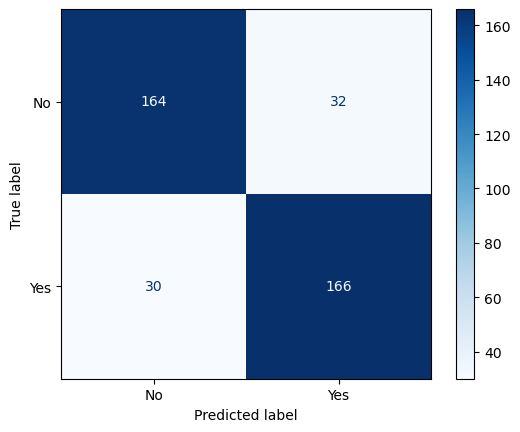

In [220]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = (model.predict(X_test) > 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"])
disp.plot(cmap="Blues")
plt.show()

In [221]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred,
                            target_names=["No", "Yes"]))

              precision    recall  f1-score   support

          No       0.85      0.84      0.84       196
         Yes       0.84      0.85      0.84       196

    accuracy                           0.84       392
   macro avg       0.84      0.84      0.84       392
weighted avg       0.84      0.84      0.84       392



In [222]:
model.save("glasses_classifier.keras")

In [223]:
val_loss, val_accuracy = model.evaluate(X_test, y_test)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.8418 - loss: 0.3567
Validation Loss: 0.3566707372665405
Validation Accuracy: 0.8418367505073547


In [224]:
y_pred = (model.predict(X_test) > 0.5).astype(int)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step


In [225]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["No","Yes"]
))

              precision    recall  f1-score   support

          No       0.85      0.84      0.84       196
         Yes       0.84      0.85      0.84       196

    accuracy                           0.84       392
   macro avg       0.84      0.84      0.84       392
weighted avg       0.84      0.84      0.84       392



In [226]:
test_case = model.predict(X_test)
test_case[11]

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step


array([0.00598469], dtype=float32)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
Prediction : yes


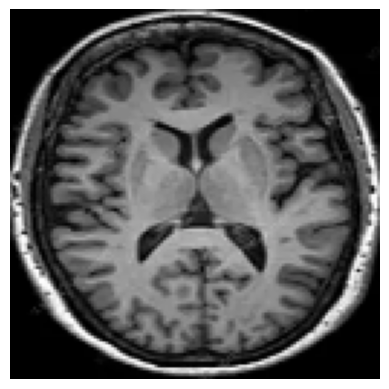

In [278]:
image_path = r"C:/Users/kapidhwaj/Downloads/tumor_no.webp"

img = cv2.imread(image_path)
img = cv2.resize(img,(128,128))

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

sobelx = cv2.Sobel(gray,cv2.CV_64F,1,0,ksize=3)
sobely = cv2.Sobel(gray,cv2.CV_64F,0,1,ksize=3)
laplacian = cv2.Laplacian(gray,cv2.CV_64F)

sobelx = cv2.convertScaleAbs(sobelx)
sobely = cv2.convertScaleAbs(sobely)
laplacian = cv2.convertScaleAbs(laplacian)

edge = cv2.merge([sobelx,sobely,laplacian])
edge_gray = cv2.cvtColor(edge,cv2.COLOR_BGR2GRAY)

combined = np.dstack((gray,edge_gray,sobelx,laplacian))
combined = combined.astype(np.float32)
combined = np.expand_dims(combined,axis=0)

prediction = model.predict(combined)

if prediction[0][0] > 0.5:
    print("Prediction : yes")
else:
    print("Prediction : no")

plt.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
Prediction : yes


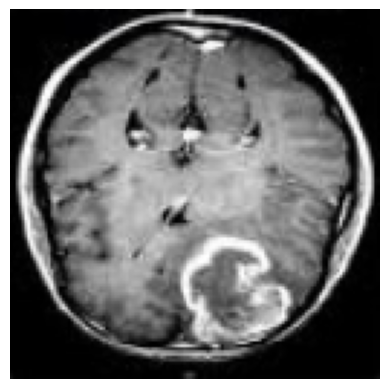

In [296]:
image_path = r"C:/Users/kapidhwaj/Downloads/kapidhh_testing2.jpg.jpeg"

img = cv2.imread(image_path)
img = cv2.resize(img,(128,128))

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

sobelx = cv2.Sobel(gray,cv2.CV_64F,1,0,ksize=3)
sobely = cv2.Sobel(gray,cv2.CV_64F,0,1,ksize=3)
laplacian = cv2.Laplacian(gray,cv2.CV_64F)

sobelx = cv2.convertScaleAbs(sobelx)
sobely = cv2.convertScaleAbs(sobely)
laplacian = cv2.convertScaleAbs(laplacian)

edge = cv2.merge([sobelx,sobely,laplacian])
edge_gray = cv2.cvtColor(edge,cv2.COLOR_BGR2GRAY)

combined = np.dstack((gray,edge_gray,sobelx,laplacian))
combined = combined.astype(np.float32)
combined = np.expand_dims(combined,axis=0)

prediction = model.predict(combined)

if prediction[0][0] > 0.5:
    print("Prediction : yes")
else:
    print("Prediction : no")

plt.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
Prediction : yes


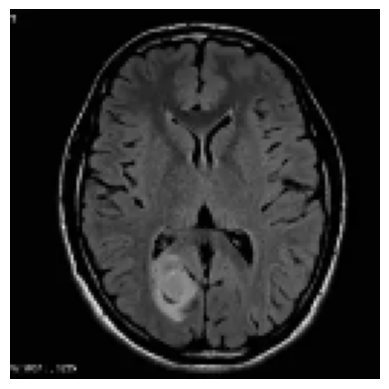

In [297]:
image_path = r"C:/Users/kapidhwaj/Downloads/tumor_yes2.webp"

img = cv2.imread(image_path)
img = cv2.resize(img,(128,128))

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

sobelx = cv2.Sobel(gray,cv2.CV_64F,1,0,ksize=3)
sobely = cv2.Sobel(gray,cv2.CV_64F,0,1,ksize=3)
laplacian = cv2.Laplacian(gray,cv2.CV_64F)

sobelx = cv2.convertScaleAbs(sobelx)
sobely = cv2.convertScaleAbs(sobely)
laplacian = cv2.convertScaleAbs(laplacian)

edge = cv2.merge([sobelx,sobely,laplacian])
edge_gray = cv2.cvtColor(edge,cv2.COLOR_BGR2GRAY)

combined = np.dstack((gray,edge_gray,sobelx,laplacian))
combined = combined.astype(np.float32)
combined = np.expand_dims(combined,axis=0)

prediction = model.predict(combined)

if prediction[0][0] > 0.5:
    print("Prediction : yes")
else:
    print("Prediction : no")

plt.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()